In [198]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# Trắc nghiệm (3đ)
# Kmeans, KNN, Logister, Linear 
# # KMeans  
# (code 7d)
# - xử lý trùng
# - xử lý thiếu
# - xử lý ngoại lệ
# - chọn đăc trưng để phân cụm
#     + mã hoá (OneHotEncoder, LabelEncoder)
#     + Log (xử lý lệch)
#     + chuẩn hoá (StandardScaler, MinMaxScaler)
# - Lưu model
# - Đọc model
# - Predict 3 dữ liệu mẫu

In [200]:
df = pd.read_csv('./tmdb_5000_movies.csv')
df.head(4)

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106


In [201]:
df.shape

(4803, 20)

In [202]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   budget                4803 non-null   int64  
 1   genres                4803 non-null   object 
 2   homepage              1712 non-null   object 
 3   id                    4803 non-null   int64  
 4   keywords              4803 non-null   object 
 5   original_language     4803 non-null   object 
 6   original_title        4803 non-null   object 
 7   overview              4800 non-null   object 
 8   popularity            4803 non-null   float64
 9   production_companies  4803 non-null   object 
 10  production_countries  4803 non-null   object 
 11  release_date          4802 non-null   object 
 12  revenue               4803 non-null   int64  
 13  runtime               4801 non-null   float64
 14  spoken_languages      4803 non-null   object 
 15  status               

In [203]:
# xem thong ke mo ta (phan tich don bien) describe
num_cols = ['budget', 'revenue','runtime','vote_average']
df[num_cols].describe()


,budget,revenue,runtime,vote_average
count,4.803000e+03,4.803000e+03,4801.000000,4803.000000
mean,2.904504e+07,8.226064e+07,106.875859,6.092172
std,4.072239e+07,1.628571e+08,22.611935,1.194612
min,0.000000e+00,0.000000e+00,0.000000,0.000000
25%,7.900000e+05,0.000000e+00,94.000000,5.600000
50%,1.500000e+07,1.917000e+07,103.000000,6.200000
75%,4.000000e+07,9.291719e+07,118.000000,6.800000
max,3.800000e+08,2.787965e+09,338.000000,10.000000


In [204]:
print(df.isna().sum())

budget                     0
genres                     0
homepage                3091
id                         0
keywords                   0
original_language          0
original_title             0
overview                   3
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                  844
title                      0
vote_average               0
vote_count                 0
dtype: int64


In [205]:
print(df[num_cols].isna().sum())

budget          0
revenue         0
runtime         2
vote_average    0
dtype: int64


Preprocessing

In [206]:
# 1. bo dong trung
df = df.drop_duplicates()
df.shape

(4803, 20)

In [207]:
# id
df = df.drop_duplicates(subset='id')
df.shape

(4803, 20)

In [208]:
# 2. xu ly du lieu thieu
# bo cac dong runtime bi thieu
df= df.dropna(subset='runtime')
df.shape

(4801, 20)

In [209]:
# bo cac phim co budget > 10000, revenue >= 10000 vote_count > 0

In [210]:
len(df[(df['budget'] >= 10000) & (df['revenue'] >=10000) &
        (df['revenue']>0) & (df['vote_count']>0)])

3204

In [211]:
df = df[(df['budget'] >= 10000) & (df['revenue'] >=10000) &
        (df['revenue']>0) & (df['vote_count']>0)]

df.shape

(3204, 20)

In [212]:
df.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count'],
      dtype='object')

In [213]:
# kiem tra lech (skewness)

df[['budget', 'revenue', 'vote_average','popularity']].skew()


budget          2.084417
revenue         3.810977
vote_average   -0.410066
popularity      9.265738
dtype: float64

skew: gan 0 (-0.5 ---> 0.5) : phan phoi doi xung, k can xu ly
        0.5 --> 1 (-0.5 ---> -1): lech vua
        > 1 (>-1): lech manh

        ==> log  

In [214]:
for c in ['budget', 'revenue', 'vote_average','popularity']:
    df['log_'+ c] = np.log1p(df[c])
df

,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,...,spoken_languages,status,tagline,title,vote_average,vote_count,log_budget,log_revenue,log_vote_average,log_popularity
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800,19.283571,21.748578,2.104134,5.020174
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500,19.519293,20.683485,2.066863,4.942232
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...",...,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466,19.316769,20.596199,1.987874,4.685614
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106,19.336971,20.804790,2.151762,4.730153
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124,19.376192,19.464974,1.960095,3.805039
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4772,31192,"[{""id"": 18, ""name"": ""Drama""}, {""id"": 28, ""name...",http://downterrace.blogspot.com/,42151,"[{""id"": 9826, ""name"": ""murder""}, {""id"": 10123,...",en,Down Terrace,After serving jail time for a mysterious crime...,1.330379,[],...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,You're only as good as the people you know.,Down Terrace,6.3,26,10.347949,9.210440,1.987874,0.846031
4773,27000,"[{""id"": 35, ""name"": ""Comedy""}]",http://www.miramax.com/movie/clerks/,2292,"[{""id"": 1361, ""name"": ""salesclerk""}, {""id"": 30...",en,Clerks,Convenience and video store clerks Dante and R...,19.748658,"[{""name"": ""Miramax Films"", ""id"": 14}, {""name"":...",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,Just because they serve you doesn't mean they ...,Clerks,7.4,755,10.203629,14.963272,2.128232,3.032482
4788,12000,"[{""id"": 27, ""name"": ""Horror""}, {""id"": 35, ""nam...",NaN,692,"[{""id"": 237, ""name"": ""gay""}, {""id"": 900, ""name...",en,Pink Flamingos,Notorious Baltimore criminal and underground f...,4.553644,"[{""name"": ""Dreamland Productions"", ""id"": 407}]",...,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,An exercise in poor taste.,Pink Flamingos,6.2,110,9.392745,15.607270,1.9740

In [215]:
# df['log_budget'] = np.log1p(df['budget'])

# df[['log_budget', 'budget']]

In [216]:
print("skew trc log", df[['budget', 'revenue', 'vote_average','popularity']].skew().round(2).to_dict())
print("skew trc log", df[['log_budget', 'log_revenue', 'log_vote_average','log_popularity']].skew().round(2).to_dict())

skew trc log {'budget': 2.08, 'revenue': 3.81, 'vote_average': -0.41, 'popularity': 9.27}
skew trc log {'log_budget': -1.15, 'log_revenue': -1.13, 'log_vote_average': -0.93, 'log_popularity': -0.37}


In [217]:
# seaborn

In [218]:
df.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count', 'log_budget', 'log_revenue', 'log_vote_average',
       'log_popularity'],
      dtype='object')

In [219]:
# 3. outlier (IQR)

feat_cols = ['log_budget', 'log_revenue','runtime','vote_average', 'log_vote_average','popularity']

In [220]:
Q1 = df[feat_cols].quantile(0.25)
Q3 = df[feat_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5*IQR
upper_bound = Q3 + 1.5*IQR

valid = ((df[feat_cols] >= lower_bound) & (df[feat_cols] <= upper_bound)).all(axis =1)

print (f"truoc: {len(df)} sau: {valid.sum()}")
        # |           |           |           |           |
        # lower       Q1          Q2            Q3        upper

truoc: 3204 sau: 2702


In [221]:
df3 = pd.concat([Q1.rename("Q1"), Q3, IQR, lower_bound,upper_bound ], axis= 1)
# df3.columns = ['Q1', 'Q3']
df3

,Q1,0.75,0,1,2
log_budget,16.213406,17.822844,1.609438,13.799249,20.237001
log_revenue,16.675087,18.811347,2.136260,13.470697,22.015738
runtime,96.000000,121.000000,25.000000,58.500000,158.500000
vote_average,5.800000,6.900000,1.100000,4.150000,8.550000
log_vote_average,1.916923,2.066863,0.149940,1.692012,2.291773
popularity,10.658131,37.514625,26.856494,-29.626610,77.799366


In [222]:
df['genres'][0]

'[{"id": 28, "name": "Action"}, {"id": 12, "name": "Adventure"}, {"id": 14, "name": "Fantasy"}, {"id": 878, "name": "Science Fiction"}]'

In [223]:
# df['main_genre']?

In [224]:
import json
json.loads(df['genres'].iloc[0])[0]['name']

'Action'

In [225]:
def first_main_genres(s):
    g = json.loads(s)
    return g[0]['name'] if g else 'unknow'

In [226]:
df['main_genre'] = df['genres'].apply(first_main_genres)
# df['main_genre'] 

# Stage 2

In [227]:
df.columns

Index(['budget', 'genres', 'homepage', 'id', 'keywords', 'original_language',
       'original_title', 'overview', 'popularity', 'production_companies',
       'production_countries', 'release_date', 'revenue', 'runtime',
       'spoken_languages', 'status', 'tagline', 'title', 'vote_average',
       'vote_count', 'log_budget', 'log_revenue', 'log_vote_average',
       'log_popularity', 'main_genre'],
      dtype='object')

original_language


main_genre 

Bien chu thanh so: OneHotEncoder  (0/1), LabelEncoder (0,1,2,3) (...;)

GioiTinh    Nu_trans    Nam_trans
Nu          1           0
Nam         0           1
Nu          1           0

GioiTinh   GioiTinh_trans 
Nu         0 
Nam        1 
Nu          



In [228]:
df[['main_genre','original_language']]

,main_genre,original_language
0,Action,en
1,Adventure,en
2,Action,en
3,Action,en
4,Action,en
...,...,...
4772,Drama,en
4773,Comedy,en
4788,Horror,en
4792,Crime,ja


In [229]:
df['main_genre'].unique()

array(['Action', 'Adventure', 'Fantasy', 'Animation', 'Science Fiction',
       'Drama', 'Thriller', 'Family', 'Comedy', 'History', 'War',
       'Western', 'Romance', 'Crime', 'Mystery', 'Horror', 'Music',
       'Documentary', 'unknow', 'Foreign'], dtype=object)

In [230]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder


In [231]:
df['original_language'].unique()

array(['en', 'ja', 'fr', 'zh', 'ko', 'te', 'ru', 'de', 'cn', 'es', 'nl',
       'th', 'da', 'xx', 'it', 'hi', 'nb', 'pt', 'af', 'pl', 'he', 'vi',
       'id', 'ro', 'no', 'fa'], dtype=object)

In [232]:
df['lang']=np.where(df['original_language']=='en', 'en', 'other')
df[['original_language','lang']]

,original_language,lang
0,en,en
1,en,en
2,en,en
3,en,en
4,en,en
...,...,...
4772,en,en
4773,en,en
4788,en,en
4792,ja,other


In [233]:
df['lang1']=df['original_language'].apply(lambda x: 'en' if x == 'en' else 'other')
df[['original_language','lang', 'lang1']]

,original_language,lang,lang1
0,en,en,en
1,en,en,en
2,en,en,en
3,en,en,en
4,en,en,en
...,...,...,...
4772,en,en,en
4773,en,en,en
4788,en,en,en
4792,ja,other,other


In [234]:
la = LabelEncoder()

df['lang_encoded'] = la.fit_transform(df['lang'])
df[['lang_encoded','lang']]

,lang_encoded,lang
0,0,en
1,0,en
2,0,en
3,0,en
4,0,en
...,...,...
4772,0,en
4773,0,en
4788,0,en
4792,1,other


In [235]:

ohe = OneHotEncoder(sparse_output=False)

main_genre_encoded = ohe.fit_transform(df[['main_genre']])
main_genre_encoded



array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]])

In [236]:
df_main_genre_encoded = pd.DataFrame(main_genre_encoded, 
                                     columns = ohe.get_feature_names_out(),
                                     index = df.index)
df_main_genre_encoded

,main_genre_Action,main_genre_Adventure,main_genre_Animation,main_genre_Comedy,main_genre_Crime,main_genre_Documentary,main_genre_Drama,main_genre_Family,main_genre_Fantasy,main_genre_Foreign,main_genre_History,main_genre_Horror,main_genre_Music,main_genre_Mystery,main_genre_Romance,main_genre_Science Fiction,main_genre_Thriller,main_genre_War,main_genre_Western,main_genre_unknow
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4772,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4773,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4788,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4792,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [237]:
# chon features
feat_cols = ['log_budget', 'log_revenue', 'runtime', 'vote_average', 'log_popularity']

In [238]:
df2 = pd.concat([df[feat_cols], df['lang_encoded'], df_main_genre_encoded], axis=1)
df2

,log_budget,log_revenue,runtime,vote_average,log_popularity,lang_encoded,main_genre_Action,main_genre_Adventure,main_genre_Animation,main_genre_Comedy,...,main_genre_History,main_genre_Horror,main_genre_Music,main_genre_Mystery,main_genre_Romance,main_genre_Science Fiction,main_genre_Thriller,main_genre_War,main_genre_Western,main_genre_unknow
0,19.283571,21.748578,162.0,7.2,5.020174,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,19.519293,20.683485,169.0,6.9,4.942232,0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,19.316769,20.596199,148.0,6.3,4.685614,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,19.336971,20.804790,165.0,7.6,4.730153,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,19.376192,19.464974,132.0,6.1,3.805039,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4772,10.347949,9.210440,89.0,6.3,0.846031,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4773,10.203629,14.963272,92.0,7.4,3.032482,0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4788,9.392745,15.607270,93.0,6.2,1.714454,0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4792,9.903538,11.502885,111.0,7.4,0.192637,1,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


* chuyen tat ca ve cung 1 do do

In [ ]:
# MinMaxScaler, StandardScaler

# - bo du lieu phai k co outlier, vd : diem 0-10, 1000, 100

# StandardScaler: 
#     - gt moi = (gt cu - mean)/std


In [240]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df2_scared = df2.copy()
df2_scared[feat_cols] = scaler.fit_transform(df2[feat_cols])

df2_scared.head()

,log_budget,log_revenue,runtime,vote_average,log_popularity,lang_encoded,main_genre_Action,main_genre_Adventure,main_genre_Animation,main_genre_Comedy,...,main_genre_History,main_genre_Horror,main_genre_Music,main_genre_Mystery,main_genre_Romance,main_genre_Science Fiction,main_genre_Thriller,main_genre_War,main_genre_Western,main_genre_unknow
0,1.739968,2.324793,2.443044,1.033354,2.168708,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.909581,1.731154,2.777241,0.683959,2.084655,0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.763856,1.682504,1.774650,-0.014831,1.807913,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.778392,1.798764,2.586271,1.499214,1.855946,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.806613,1.052006,1.010771,-0.247761,0.858285,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [241]:
df2_scared[feat_cols].describe().round(2)

,log_budget,log_revenue,runtime,vote_average,log_popularity
count,3204.00,3204.00,3204.00,3204.00,3204.00
mean,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-5.51,-4.66,-3.33,-4.67,-3.22
25%,-0.47,-0.50,-0.71,-0.60,-0.60
50%,0.14,0.15,-0.18,-0.01,0.07
75%,0.69,0.69,0.49,0.68,0.69
max,2.08,2.32,10.85,2.55,4.06


<!-- * K (Elbow + Silhoutte)

-- hinh: K 
-- k = 2 (*) -->

In [245]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters= 4, n_init=10, random_state=42)

df['cluster']=km.fit_predict(df2_scared)
df['cluster'].value_counts().sort_index()

cluster
0     680
1    1161
2     537
3     826
Name: count, dtype: int64

In [246]:
df.groupby('cluster')[['budget','revenue', 'runtime']].median()

,budget,revenue,runtime
cluster,,,
0,4619391.5,6946000.0,103.5
1,45000000.0,129394835.0,107.0
2,39000000.0,122126687.0,137.0
3,25000000.0,33000168.5,99.0


In [247]:
genre_share = pd.crosstab(df['cluster'], df['main_genre'], normalize='index').round(2)
top_genres = genre_share.mean().sort_values(ascending=False).head(8).index
genre_share[top_genres]

main_genre,Drama,Comedy,Action,Adventure,Horror,Crime,Thriller,Fantasy
cluster,,,,,,,,
0,0.37,0.19,0.10,0.05,0.06,0.06,0.03,0.01
1,0.13,0.20,0.22,0.11,0.06,0.04,0.04,0.05
2,0.44,0.05,0.16,0.13,0.01,0.06,0.03,0.02
3,0.13,0.30,0.22,0.06,0.09,0.03,0.05,0.02


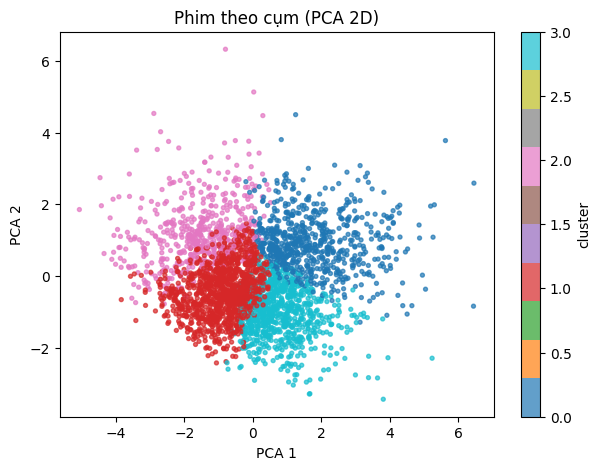

Phương sai giải thích: [0.4  0.23]


In [248]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
p = pca.fit_transform(df2_scared)

plt.figure(figsize=(7, 5))
plt.scatter(p[:, 0], p[:, 1], c=df['cluster'], cmap='tab10', s=8, alpha=0.7)
plt.xlabel('PCA 1'); plt.ylabel('PCA 2')
plt.title('Phim theo cụm (PCA 2D)')
plt.colorbar(label='cluster')
plt.show()
print('Phương sai giải thích:', pca.explained_variance_ratio_.round(2))

In [ ]:
import joblib 

joblib.dump({
    'kmeans': km,
    'ohe': ohe,
    'scaler' : scaler,
    'feat_cols': feat_cols
},'kmean.joblib')

['kmean.joblib']

In [255]:
a = joblib.load('kmean.joblib')
a.keys()

dict_keys(['kmeans', 'ohe', 'scaler', 'feat_cols'])

In [ ]:
# ? du lieu test 3 du lieu mau